# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

---
## Chuẩn bị chung

Làm theo Lab 2 (Phần A và B.7): cả bốn bài dùng **cùng một phép chia dữ liệu, cùng seed 42** và cùng khung huấn luyện/đánh giá. Mỗi bài chỉ cần gọi `train_and_report(...)`; kết quả của mọi lần chạy được gom vào `RESULTS` để lập bảng tổng hợp ở cuối.

In [1]:
import json
import os
import random
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

SEED = 42


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch  :", torch.__version__)
print("device :", device)


# Hai hàm tiện ích của Lab 2 (A.1)
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)


def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")

torch  : 2.11.0+cu128
device : cuda


In [2]:
# Cấu hình chung cho cả bốn bài (Lab 2, A.2 Bước 2)
DATA_ROOT = Path("/kaggle/input/datasets/sonbui25/vinafood21/VinaFood21") 
GDRIVE_URL = "https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view"

BATCH = 32
NUM_WORKERS = 0 if os.name == "nt" else 2
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # mean/std của ImageNet

IMG_SIZE = 64      
R18_SIZE = 96      
R50_SIZE = 224     
EPOCHS = 20       
EPOCHS_R50 = 5    


def find_data_root(search_dir):
    # Tìm thư mục cha của train/ trong cây thư mục vừa giải nén
    for p in sorted(Path(search_dir).rglob("train")):
        if p.is_dir() and any(c.is_dir() for c in p.iterdir()):
            return p.parent
    return None


if not (DATA_ROOT / "train").is_dir():
    # Chưa có dữ liệu: thử tải tự động (Colab). Nếu lỗi thì tải tay theo link ở đầu notebook
    try:
        import shutil
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
        import gdown
        gdown.download(GDRIVE_URL, "vinafood21.zip", quiet=False, fuzzy=True)
        shutil.unpack_archive("vinafood21.zip", "vinafood21_raw")
        DATA_ROOT = find_data_root("vinafood21_raw") or DATA_ROOT
    except Exception as e:
        print("Không tải được tự động:", type(e).__name__, "-", e)

HAS_DATA = (DATA_ROOT / "train").is_dir()
READY = HAS_DATA
print("Tìm thấy dữ liệu:", HAS_DATA, "-", DATA_ROOT.resolve())

CLASSES = [f"lop_{i}" for i in range(21)]
if READY:
    CLASSES = sorted(d.name for d in (DATA_ROOT / "train").iterdir() if d.is_dir())
NUM_CLASSES = len(CLASSES)

Tìm thấy dữ liệu: True - /kaggle/input/datasets/sonbui25/vinafood21/VinaFood21


In [3]:
# Transform và DataLoader 
def build_transforms(img_size, augment=True):
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    if not augment:
        return eval_tf, eval_tf
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return train_tf, eval_tf


def split_indices(n, has_val, has_test):
    # Cùng một phép chia cho mọi bài: random_split + generator seed 42.
    n_val = 0 if has_val else int(0.1 * n)
    n_test = 0 if has_test else int(0.1 * n)
    lengths = [n - n_val - n_test, n_val, n_test]
    parts = random_split(range(n), lengths, generator=torch.Generator().manual_seed(SEED))
    return [p.indices for p in parts]


_LOADER_CACHE = {}


def get_loaders(img_size, augment=True):
    key = (img_size, augment)
    if key in _LOADER_CACHE:
        return _LOADER_CACHE[key]

    train_tf, eval_tf = build_transforms(img_size, augment)
    full_train = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
    full_eval = datasets.ImageFolder(DATA_ROOT / "train", transform=eval_tf)
    assert full_train.classes == CLASSES

    val_dir, test_dir = DATA_ROOT / "val", DATA_ROOT / "test"
    has_val = val_dir.is_dir()
    has_test = test_dir.is_dir() and any(p.is_dir() for p in test_dir.iterdir())
    train_idx, val_idx, test_idx = split_indices(len(full_train), has_val, has_test)

    train_ds = Subset(full_train, train_idx)
    val_ds = datasets.ImageFolder(val_dir, eval_tf) if has_val else Subset(full_eval, val_idx)
    test_ds = datasets.ImageFolder(test_dir, eval_tf) if has_test else Subset(full_eval, test_idx)
    if not has_test:
        print("Không có test/ có nhãn: tách 10% từ train làm test (seed 42).")

    kw = dict(batch_size=BATCH, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
    loaders = (
        DataLoader(train_ds, shuffle=True, generator=torch.Generator().manual_seed(SEED), **kw),
        DataLoader(val_ds, shuffle=False, **kw),
        DataLoader(test_ds, shuffle=False, **kw),
    )
    _LOADER_CACHE[key] = loaders
    return loaders

số lớp         : 21
train/val/test : 9040 / 1004 / 6682
thứ tự lớp     : ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron'] ...
một ảnh sau transform        (3, 64, 64)
một batch vào model          (32, 3, 64, 64)
nhãn                         (32,)

ảnh/lớp (train gốc): min 215, max 910, tỉ lệ max/min 4.23


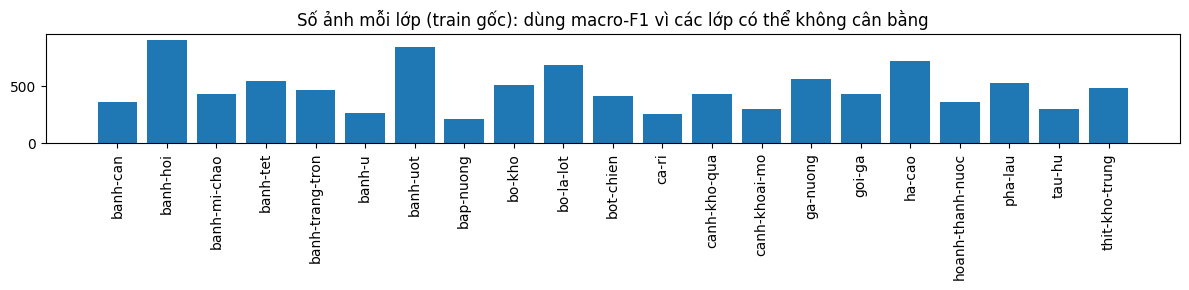

In [4]:
# Kiểm tra dữ liệu: shape một ảnh / một batch và phân phối lớp
if READY:
    train_dl, val_dl, test_dl = get_loaders(IMG_SIZE, augment=True)
    print("số lớp         :", NUM_CLASSES)
    print("train/val/test :", len(train_dl.dataset), "/", len(val_dl.dataset), "/", len(test_dl.dataset))
    print("thứ tự lớp     :", CLASSES[:5], "...")

    anh, nhan = train_dl.dataset[0]
    xb, yb = next(iter(train_dl))
    show("một ảnh sau transform", anh)
    show("một batch vào model", xb)
    show("nhãn", yb)

    counts = np.bincount(datasets.ImageFolder(DATA_ROOT / "train").targets, minlength=NUM_CLASSES)
    print(f"\nảnh/lớp (train gốc): min {counts.min()}, max {counts.max()}, tỉ lệ max/min {counts.max() / counts.min():.2f}")
    plt.figure(figsize=(12, 3))
    plt.bar(range(NUM_CLASSES), counts)
    plt.xticks(range(NUM_CLASSES), CLASSES, rotation=90)
    plt.title("Số ảnh mỗi lớp (train gốc): dùng macro-F1 vì các lớp có thể không cân bằng")
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có dữ liệu: các ô huấn luyện sẽ tự bỏ qua, phần kiểm tra kiến trúc vẫn chạy.")

In [5]:
# Khung huấn luyện và đánh giá 
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                     # bật dropout, BN dùng thống kê batch
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                      # tắt dropout, BN dùng thống kê tích luỹ
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred


def fit(model, train_dl, val_dl, criterion, optimizer, epochs):
    # Huấn luyện, ghi lịch sử; cuối cùng nạp lại trọng số của epoch có val loss thấp nhất
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "sec": []}
    best_loss, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_dl, criterion, device)
        hist["sec"].append(time.perf_counter() - t0)
        for k, v in zip(("train_loss", "train_acc", "val_loss", "val_acc"), (tr_loss, tr_acc, va_loss, va_acc)):
            hist[k].append(v)
        if va_loss < best_loss:
            best_loss, hist["best_epoch"] = va_loss, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}   val {va_loss:.4f}/{va_acc:.4f}   {hist['sec'][-1]:.1f}s")
    model.load_state_dict(best_state)
    return hist


def split_epoch(hist, thr=0.1):
    # Epoch đầu tiên val loss vượt train loss quá thr (tương đối): hai đường bắt đầu tách nhau
    for ep, (t, v) in enumerate(zip(hist["train_loss"], hist["val_loss"]), 1):
        if v > (1 + thr) * t:
            return ep
    return None


def plot_curves(hist, title, mark_split=False):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(ep, hist["train_loss"], label="train loss")
    ax[0].plot(ep, hist["val_loss"], label="val loss")
    ax[0].axvline(hist["best_epoch"], color="gray", ls=":", label=f"val loss thấp nhất (epoch {hist['best_epoch']})")
    se = split_epoch(hist)
    if mark_split and se:
        ax[0].axvline(se, color="red", ls="--", label=f"hai đường tách nhau (epoch {se})")
    ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("loss")
    ax[0].legend()
    ax[1].plot(ep, hist["train_acc"], label="train acc")
    ax[1].plot(ep, hist["val_acc"], label="val acc")
    ax[1].set_xlabel("epoch")
    ax[1].set_ylabel("accuracy")
    ax[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


RESULTS = {}   # tag -> dict kết quả, dùng cho bảng tổng hợp
RESULTS_DIR = Path("results")  
RESULTS_DIR.mkdir(exist_ok=True)


def save_result(tag):
    slug = "".join(ch if ch.isalnum() else "_" for ch in tag.lower())
    light = {k: v for k, v in RESULTS[tag].items() if k not in ("y_true", "y_pred")}
    with open(RESULTS_DIR / f"{slug}.json", "w", encoding="utf-8") as f:
        json.dump({"tag": tag, **light}, f, ensure_ascii=False, default=float)


def load_results():
    for p in sorted(RESULTS_DIR.glob("*.json")):
        with open(p, encoding="utf-8") as f:
            r = json.load(f)
        RESULTS.setdefault(r.pop("tag"), r)


def show_report(tag, res, mark_split=False):
    hist, y_true, y_pred = res["hist"], res["y_true"], res["y_pred"]
    print(f"\n--- {tag}: kết quả trên tập test (nạp lại epoch {hist['best_epoch']}) ---")
    print(f"tham số: {res['params']:,} (được học: {res['trainable']:,}) | {res['sec_epoch']:.1f} giây/epoch")
    display(pd.DataFrame({
        "accuracy": [res["accuracy"]], "precision (macro)": [res["precision"]],
        "recall (macro)": [res["recall"]], "F1 (macro)": [res["macro_f1"]],
    }, index=[tag]).round(4))

    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), average=None, zero_division=0)
    display(pd.DataFrame({"lớp": CLASSES, "precision": p, "recall": r, "F1": f, "số ảnh test": s}).round(4))

    plot_curves(hist, tag, mark_split)

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(13, 11))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES,
                annot_kws={"size": 6}, cbar=False)
    plt.xlabel("dự đoán")
    plt.ylabel("thực tế")
    plt.title(f"Confusion matrix {NUM_CLASSES}x{NUM_CLASSES}: {tag}")
    plt.tight_layout()
    plt.show()

    off = cm.copy()
    np.fill_diagonal(off, 0)
    print("Top 5 cặp bị nhầm nhiều nhất (thực tế -> dự đoán):")
    for i, j in zip(*np.unravel_index(np.argsort(-off, axis=None)[:5], off.shape)):
        if off[i, j] > 0:
            print(f"  {CLASSES[i]} -> {CLASSES[j]}: {off[i, j]} ảnh")


def train_and_report(tag, make_model, img_size, lr, epochs, augment=True, mark_split=False):
    if not READY:
        print(f"[{tag}] chưa có dữ liệu VinaFood21 -> bỏ qua huấn luyện.")
        return None
    train_dl, val_dl, test_dl = get_loaders(img_size, augment)
    seed_everything()
    model = make_model().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)   # chỉ tham số cần học
    print(f"== {tag} | resize {img_size} | augment={augment} | Adam lr={lr} | "
          f"tham số {n_params(model):,} (được học {n_params(model, True):,})")

    hist = fit(model, train_dl, val_dl, criterion, optimizer, epochs)
    _, _, y_true, y_pred = evaluate(model, test_dl, criterion, device)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    RESULTS[tag] = dict(
        resize=f"{img_size}x{img_size}", params=n_params(model), trainable=n_params(model, True),
        sec_epoch=float(np.mean(hist["sec"])), accuracy=accuracy_score(y_true, y_pred),
        precision=p, recall=r, macro_f1=f1, hist=hist, y_true=y_true, y_pred=y_pred)
    save_result(tag)
    show_report(tag, RESULTS[tag], mark_split)
    return model


def compare_models(names):
    names = [n for n in names if n in RESULTS]
    return pd.DataFrame({
        n: {"tham số": RESULTS[n]["params"], "giây/epoch": RESULTS[n]["sec_epoch"],
            "accuracy": RESULTS[n]["accuracy"], "macro-F1": RESULTS[n]["macro_f1"]}
        for n in names}).T.round(4)


load_results()   

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**

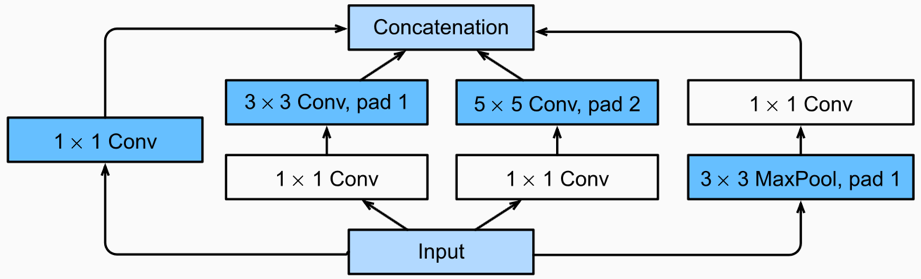

**GoogLeNet (Multi-branch Network)**

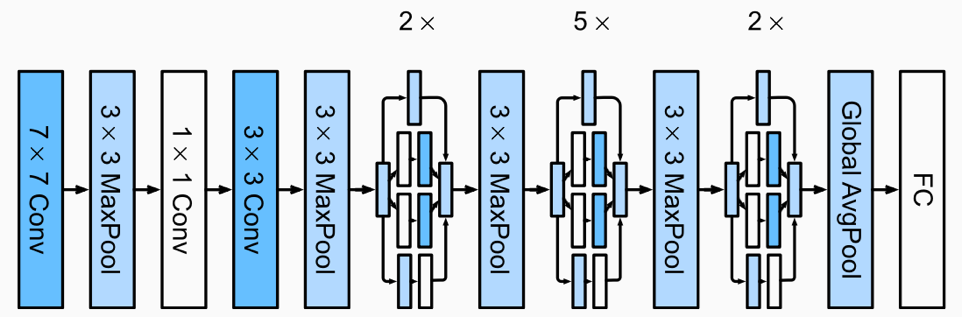

In [6]:
# Inception block 
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1), nn.ReLU())

    def forward(self, x):
        # dim=1 là chiều channel
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)


# Đối chiếu hai block mẫu của Lab 2
blk_a = InceptionBlock(1, 16, 16, 24, 4, 8, 8)
blk_b = InceptionBlock(56, 32, 32, 48, 8, 16, 16)
assert blk_a(torch.rand(1, 1, 28, 28)).shape[1] == 56 and n_params(blk_a) == 4_376
assert blk_b(torch.rand(1, 56, 14, 14)).shape[1] == 112 and n_params(blk_b) == 22_104
print("Block (1, 16, 16, 24, 4, 8, 8)    : 56 channel,  4,376 tham số")
print("Block (56, 32, 32, 48, 8, 16, 16) : 112 channel, 22,104 tham số")


# GoogLeNet rút gọn: stem + 4 Inception block, MaxPool 2x2 sau block 2 và 3
class MiniGoogLeNet(nn.Module):
    CFG = [  # (f1, f3r, f3, f5r, f5, fp)
        (16, 16, 24, 4, 8, 8),
        (32, 32, 48, 8, 16, 16),
        (48, 48, 64, 8, 16, 16),
        (64, 64, 96, 16, 32, 32),
    ]

    def __init__(self, in_ch=3, num_classes=21, stem_ch=32, cfg=None, pool_after=(1, 2)):
        super().__init__()
        self.cfg = cfg or self.CFG
        self.pool_after = set(pool_after)
        self.stem = nn.Sequential(nn.Conv2d(in_ch, stem_ch, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2))
        self.pool = nn.MaxPool2d(2, 2)
        blocks, c = [], stem_ch
        for f in self.cfg:
            blocks.append(InceptionBlock(c, *f))
            c = f[0] + f[2] + f[4] + f[5]          # channel ra = f1 + f3 + f5 + fp
        self.blocks = nn.ModuleList(blocks)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.4), nn.Linear(c, num_classes))

    def forward(self, x):
        x = self.stem(x)
        for i, blk in enumerate(self.blocks):
            x = blk(x)
            if i in self.pool_after:
                x = self.pool(x)
        return self.head(self.gap(x))


def trace_inception(model, img=IMG_SIZE, in_ch=3):
    # In shape sau mỗi block: channel ra tính tay (f1+f3+f5+fp) và đo từ code phải khớp nhau
    x = model.stem(torch.zeros(1, in_ch, img, img))
    print(f"{'stem':<7}{'':>4}  {'':<24}{'':<18}{'':>5}  {str(tuple(x.shape)):<20}")
    print(f"{'block':<7}{'in':>4}  {'(f1,f3r,f3,f5r,f5,fp)':<24}{'tính tay':<18}{'code':>5}  {'output shape':<20}{'tham số':>9}")
    with torch.no_grad():
        for i, (blk, f) in enumerate(zip(model.blocks, model.cfg)):
            c_in = x.shape[1]
            x = blk(x)
            hand = f[0] + f[2] + f[4] + f[5]
            measured = x.shape[1]
            assert measured == hand
            shape_out, note = tuple(x.shape), ""
            if i in model.pool_after:
                x = model.pool(x)
                note = f"  -> MaxPool {tuple(x.shape)}"
            print(f"{'inc' + str(i + 1):<7}{c_in:>4}  {str(f):<24}{f'{f[0]}+{f[2]}+{f[4]}+{f[5]}={hand}':<18}"
                  f"{measured:>5}  {str(shape_out):<20}{n_params(blk):>9,}{note}")
        out = model.head(model.gap(x))
    print(f"GAP -> {tuple(model.gap(x).shape)}; logits {tuple(out.shape)}")


googlenet = MiniGoogLeNet(3, NUM_CLASSES).eval()
trace_inception(googlenet)
print("\nTổng tham số:", f"{n_params(googlenet):,}")
assert googlenet(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE)).shape == (2, NUM_CLASSES)

Block (1, 16, 16, 24, 4, 8, 8)    : 56 channel,  4,376 tham số
Block (56, 32, 32, 48, 8, 16, 16) : 112 channel, 22,104 tham số
stem                                                          (1, 32, 32, 32)     
block    in  (f1,f3r,f3,f5r,f5,fp)   tính tay           code  output shape          tham số
inc1     32  (16, 16, 24, 4, 8, 8)   16+24+8+8=56         56  (1, 56, 32, 32)         5,740
inc2     56  (32, 32, 48, 8, 16, 16) 32+48+16+16=112     112  (1, 112, 32, 32)       22,104  -> MaxPool (1, 112, 16, 16)
inc3    112  (48, 48, 64, 8, 16, 16) 48+64+16+16=144     144  (1, 144, 16, 16)       44,488  -> MaxPool (1, 144, 8, 8)
inc4    144  (64, 64, 96, 16, 32, 32)64+96+32+32=224     224  (1, 224, 8, 8)         93,744
GAP -> (1, 224, 1, 1); logits (1, 21)

Tổng tham số: 171,697


== GoogLeNet rút gọn | resize 64 | augment=True | Adam lr=0.001 | tham số 171,697 (được học 171,697)


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1  train 2.9650/0.0928   val 2.8699/0.1365   272.9s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2  train 2.7342/0.1558   val 2.7085/0.1514   85.9s


...

epoch 19  train 1.7931/0.4429   val 1.7495/0.4641   81.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20  train 1.7784/0.4532   val 1.7130/0.4701   81.7s

--- GoogLeNet rút gọn: kết quả trên tập test (nạp lại epoch 20) ---
tham số: 171,697 (được học: 171,697) | 93.9 giây/epoch


,accuracy,precision (macro),recall (macro),F1 (macro)
GoogLeNet rút gọn,0.4228,0.4427,0.3989,0.3962


,lớp,precision,recall,F1,số ảnh test
0,banh-can,0.3497,0.2075,0.2604,241
1,banh-hoi,0.3915,0.6244,0.4813,607
2,banh-mi-chao,0.4469,0.4221,0.4342,289
3,banh-tet,0.5161,0.4835,0.4993,364
4,banh-trang-tron,0.2688,0.0809,0.1244,309
5,banh-u,0.5600,0.2386,0.3347,176
6,banh-uot,0.3754,0.4571,0.4122,560
7,bap-nuong,0.6250,0.0699,0.1258,143
8,bo-kho,0.4063,0.5325,0.4609,338
9,bo-la-lot,0.5712,0.6747,0.6186,458


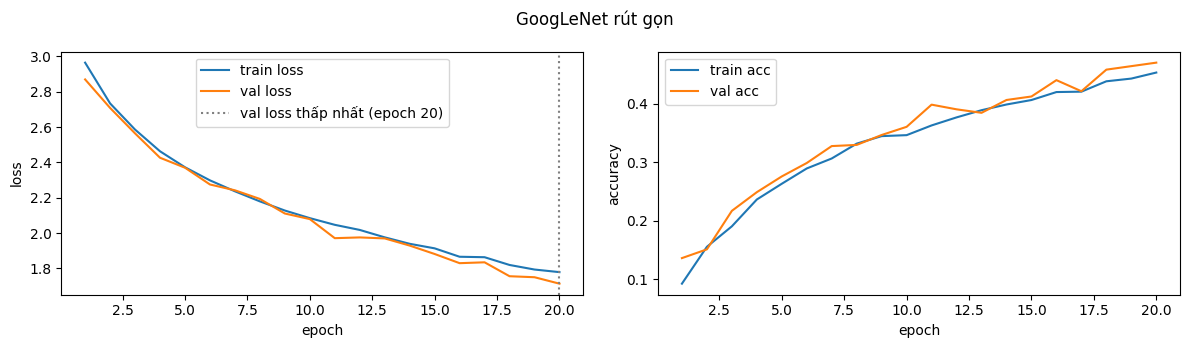

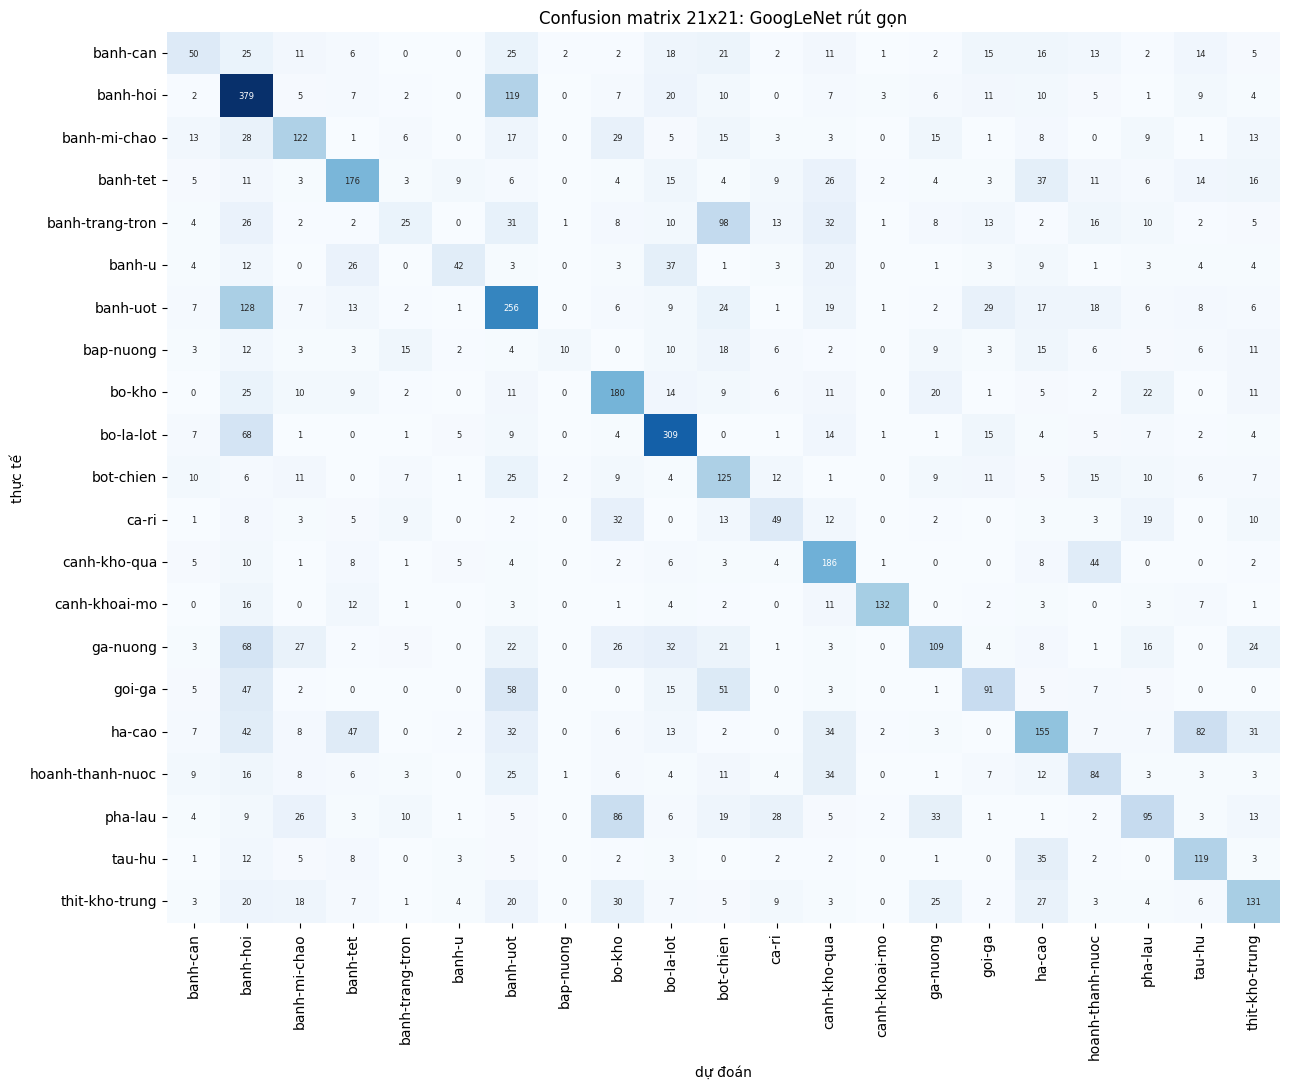

Top 5 cặp bị nhầm nhiều nhất (thực tế -> dự đoán):
  banh-uot -> banh-hoi: 128 ảnh
  banh-hoi -> banh-uot: 119 ảnh
  banh-trang-tron -> bot-chien: 98 ảnh
  pha-lau -> bo-kho: 86 ảnh
  ha-cao -> tau-hu: 82 ảnh


,tham số,giây/epoch,accuracy,macro-F1
GoogLeNet rút gọn,171697.0,93.9495,0.4228,0.3962


In [7]:
# Huấn luyện + đánh giá GoogLeNet rút gọn (Adam, lr 1e-3, resize 64x64 như Bài 1)
_ = train_and_report("GoogLeNet rút gọn", lambda: MiniGoogLeNet(3, NUM_CLASSES),
                     IMG_SIZE, lr=1e-3, epochs=EPOCHS)

# So sánh với Bài 1 về số tham số, thời gian mỗi epoch và macro-F1
display(compare_models(["LeNet-5 (AvgPool)", "LeNet-5 (MaxPool)", "GoogLeNet rút gọn"]))

---
## Bảng tổng hợp kết quả

In [8]:
# Bảng tổng hợp lấy từ các lần chạy ở trên 
ORDER = ["LeNet-5 (AvgPool)", "LeNet-5 (MaxPool)", "GoogLeNet rút gọn", "ResNet-18 từ đầu (có augment)",
         "ResNet-18 từ đầu (không augment)", "ResNet-50 feature extraction", "ResNet-50 fine-tuning"]
rows = [{
    "Mô hình": tag, "Resize": r["resize"], "Tham số": f"{r['params']:,}",
    "Tham số được học": f"{r['trainable']:,}", "Giây/epoch": round(r["sec_epoch"], 1),
    "Accuracy": round(r["accuracy"], 4), "macro-F1": round(r["macro_f1"], 4),
} for tag, r in sorted(RESULTS.items(), key=lambda kv: ORDER.index(kv[0]) if kv[0] in ORDER else 99)]

if rows:
    summary = pd.DataFrame(rows)
    display(summary)
    summary.to_csv("ket_qua_tong_hop.csv", index=False)
else:
    print("Chưa có kết quả huấn luyện (thiếu dữ liệu).")

,Mô hình,Resize,Tham số,Tham số được học,Giây/epoch,Accuracy,macro-F1
0,GoogLeNet rút gọn,64x64,"171,697","171,697",93.9,0.4228,0.3962
